# DATA 430 Project 2: Exploratory analysis of the cleansed data

This notebook looks at one pipeline run: the raw data with its injected quality problems, what Spark
removed or fixed, and the analytics that ended up in PostgreSQL.

**How to open it:** `docker compose --profile notebook up -d`, then go to http://localhost:8888
(the token is `JUPYTER_TOKEN` in `.env`). Run the cells top to bottom. Each cell builds on the ones above it.

## 1. Setup: find the most recent pipeline run

In [1]:
import os, json, glob
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = os.getenv("PIPELINE_DATA_DIR", "../data")
run_dirs = sorted((p for p in glob.glob(f"{DATA_DIR}/cleaned/*") if os.path.isdir(p)), key=os.path.getmtime)
runs = [os.path.basename(p) for p in run_dirs]
RUN_ID = runs[-1]          # most recent run; or set one explicitly, e.g. RUN_ID = "20261107T110000"
print("available runs:", runs)
print("using run:", RUN_ID)

RAW = f"{DATA_DIR}/raw/{RUN_ID}"
CLEAN = f"{DATA_DIR}/cleaned/{RUN_ID}"
REPORTS = f"{DATA_DIR}/reports/{RUN_ID}"
ANALYTICS = f"{DATA_DIR}/analytics/{RUN_ID}"
pd.set_option("display.max_columns", 20); pd.set_option("display.width", 200)

available runs: ['20261107T110000', '20261108T194920', '20261108T205528']
using run: 20261108T205528


In [2]:
# One consistent chart style for every figure in this notebook
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # categorical slots 1-3, fixed order
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

def style(ax, title, xlabel=None, ylabel=None):
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_facecolor(SURFACE); ax.figure.set_facecolor(SURFACE)
    if xlabel: ax.set_xlabel(xlabel, color=MUTED)
    if ylabel: ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(True, axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]: ax.spines[s].set_color("#c9c8c2")
    ax.tick_params(colors=MUTED)
    return ax

## 2. Raw data: what the quality problems look like

In [3]:
raw_customers = pd.read_csv(f"{RAW}/customers.csv", dtype=str, keep_default_na=False, on_bad_lines="skip", engine="python")
print(f"{len(raw_customers):,} raw customer rows")
raw_customers.sample(8, random_state=7)

105,061 raw customer rows


,customer_id,first_name,last_name,email,phone,city,registration_date,customer_type
84968,87808,Don,Vincent,don.vincent87808@fuentes.com,(258) 308-9684,Tampa,2021-05-01,Regular
87309,84438,Kayla,Alexander,kayla.alexander84438@morgan.biz,397.929.9290,Cincinnati,10/11/2021,REGULAR
19477,46075,Angelica,Dodson,angelica.dodson46075@levy.com,926-635-4374,San Diego,"Jun 3, 2025",Regular
88223,44913,Amber,Copeland,amber.copeland44913@landry.net,268-808-2206,TUCSON,2023-08-31,Regular
69707,62823,Alexis,Schultz,alexis.schultz62823@flores-diaz.com,+1 365 404 5291,San Antonio,"Aug 17, 2024",Regular
81338,12852,Alexandra,Adams,alexandra.adams12852@hawkins-herrera.net,753-718-0541,dallas,,Premium
74113,81763,Suzanne,Stevens,suzanne.stevens81763@merritt.com,344.399.6093,detroit,"Nov 3, 2025",Regular
83932,16605,Tommy,Torres,tommy.torres16605@acosta.net,392-334-5577,Cincinnati,"Jun 28, 2021",REGULAR


In [4]:
# Count each type of problem in the raw customers file
s = raw_customers.replace("", None)
problems = {
    "duplicate customer_id rows": int(s["customer_id"].duplicated(keep=False).sum()),
    "null email": int(s["email"].isna().sum()),
    "leading/trailing whitespace (any column)": int(s.apply(lambda c: c.str.contains(r"^\s|\s$", na=False)).any(axis=1).sum()),
    "city not in Title Case": int((s["city"].str.strip() != s["city"].str.strip().str.title()).sum()),
    "date not ISO (MM/DD/YYYY or 'Mon d, yyyy')": int((~s["registration_date"].fillna("2000-01-01").str.match(r"^\d{4}-\d{2}-\d{2}$")).sum()),
}
pd.Series(problems, name="rows").to_frame()

,rows
duplicate customer_id rows,10292
null email,3895
leading/trailing whitespace (any column),23680
city not in Title Case,33500
"date not ISO (MM/DD/YYYY or 'Mon d, yyyy')",31281


In [5]:
# The same city spelled many ways in the raw file
raw_customers["city"].str.strip().loc[lambda c: c.str.lower() == "new york"].value_counts()

city
New York    1567
new york     362
NEW YORK     328
Name: count, dtype: int64

In [6]:
# Ground truth written by generate_data.py: exactly what was injected
manifest = json.load(open(f"{RAW}/generation_manifest.json"))
pd.Series({k: v for k, v in manifest.items() if k.startswith("orders.")}, name="injected").to_frame()

,injected
orders.amount_with_dollar_sign,1975
orders.base_records,100000
orders.discount_exceeds_total,1008
orders.exact_duplicates,2060
orders.future_order_date,530
orders.malformed_lines,3
orders.near_duplicates,3000
orders.negative_total_amount,952
orders.null_customer_id,434
orders.null_discount_amount,1599


## 3. What Spark did: records in, out and dropped

In [7]:
summary = pd.read_csv(f"{REPORTS}/cleansing_summary.csv")
summary[["entity", "records_in", "records_out", "records_dropped", "pct_dropped"]]

,entity,records_in,records_out,records_dropped,pct_dropped
0,customers,105064,99669,5395,5.13
1,products,105064,99714,5350,5.09
2,orders,105063,94356,10707,10.19
3,order_items,243555,218417,25138,10.32


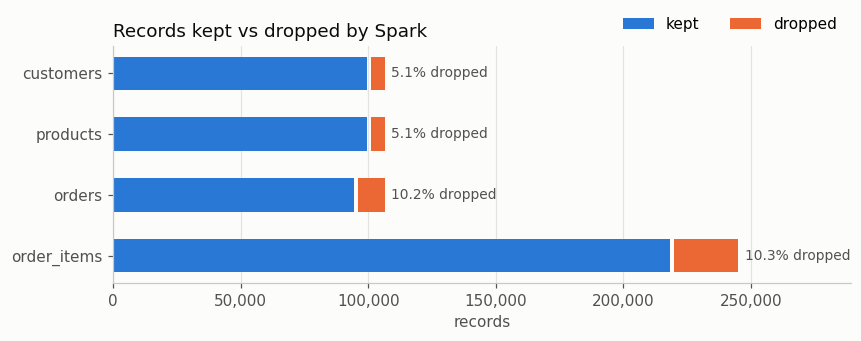

In [8]:
# Kept vs dropped per entity
fig, ax = plt.subplots(figsize=(8, 3.2), dpi=110)
y = range(len(summary))
ax.barh(y, summary["records_out"], color=BLUE, height=0.55, label="kept")
ax.barh(y, summary["records_dropped"], left=summary["records_out"] + 1500, color=ORANGE, height=0.55, label="dropped")
ax.set_yticks(list(y), summary["entity"])
for i, r in summary.iterrows():
    ax.text(r["records_in"] + 4000, i, f"{r['pct_dropped']:.1f}% dropped", va="center", color=MUTED, fontsize=9)
style(ax, "Records kept vs dropped by Spark", xlabel="records")
ax.grid(True, axis="x", color=GRID); ax.grid(False, axis="y"); ax.invert_yaxis()
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncol=2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}")); ax.margins(x=0.18)
plt.tight_layout(); plt.show()

In [9]:
# Why records were dropped (one row per entity x reason)
reasons = []
for path in sorted(glob.glob(f"{REPORTS}/cleanse_*.json")):
    st = json.load(open(path))
    for reason, n in st["dropped_by_reason"].items():
        if n: reasons.append({"entity": st["entity"], "reason": reason, "dropped": n})
reasons = pd.DataFrame(reasons)
reasons.pivot_table(index="reason", columns="entity", values="dropped", fill_value=0).astype(int)

entity,customers,order_items,orders,products
reason,,,,
discount_exceeds_total,0,0,957,0
exact_duplicate,2078,4799,2102,2082
impossible_order_date,0,0,537,0
invalid_primary_key,50,0,0,0
invalid_quantity,0,1180,0,0
malformed_record,4,2,3,4
missing_order_date,0,0,513,0
missing_total_amount,0,0,16,0
missing_unit_price,0,54,0,0


In [10]:
# Values that were repaired while the record was kept (the dq_flags column)
fixes = []
for path in sorted(glob.glob(f"{REPORTS}/cleanse_*.json")):
    st = json.load(open(path))
    for flag, n in st["records_flagged_by_fix"].items():
        fixes.append({"entity": st["entity"], "fix": flag, "records": n})
pd.DataFrame(fixes).sort_values("records", ascending=False).head(15)

,entity,fix,records
2,customers,date_format_standardized,29727
27,products,date_format_standardized,29699
0,customers,city_case_standardized,29563
17,orders,date_format_standardized,28351
14,customers,phone_format_standardized,24596
26,products,category_case_standardized,14739
23,orders,status_case_standardized,14083
22,orders,payment_method_standardized,13885
1,customers,customer_type_case_standardized,9531
25,products,boolean_format_standardized,7290


In [11]:
# Rejected records are kept for auditing, with the reason
rejected = pd.read_parquet(f"{DATA_DIR}/rejected/{RUN_ID}/orders")
rejected.groupby("reject_reason").head(1)[["reject_reason", "record"]]

,reject_reason,record
0,malformed_record,"{""order_id"":""ORDER"",""customer_id"":""BROKEN"",""_c..."
3,exact_duplicate,"{""customer_id"":""16863"",""order_date"":""2024-09-1..."
2105,null_primary_key,"{""order_date"":""2025-11-18 21:45:12"",""order_sta..."
2444,null_or_invalid_customer_id,"{""order_id"":""10287"",""order_date"":""2025-07-02 1..."
2877,missing_order_date,"{""order_id"":""10417"",""customer_id"":""23582"",""ord..."
3390,unparseable_order_date,"{""order_id"":""11196"",""customer_id"":""16471"",""ord..."
3621,impossible_order_date,"{""order_id"":""10272"",""customer_id"":""79346"",""ord..."
4158,near_duplicate,"{""order_id"":""69"",""customer_id"":""17712"",""order_..."
7016,orphan_customer,"{""customer_id"":""105812"",""order_id"":""173"",""orde..."
8845,missing_total_amount,"{""order_id"":""14833"",""customer_id"":""6336"",""orde..."


## 4. Before vs after for the same records

In [12]:
clean_customers = pd.read_parquet(f"{CLEAN}/customers")
ids = clean_customers.loc[clean_customers["dq_flags"].fillna("").str.contains("city_case|phone_format"), "customer_id"].head(5)
before = raw_customers[raw_customers["customer_id"].str.strip().isin(ids.astype(str))].drop_duplicates("customer_id")
after = clean_customers[clean_customers["customer_id"].isin(ids)]
print("BEFORE (raw)"); display(before[["customer_id", "first_name", "city", "phone", "registration_date", "customer_type"]])
print("AFTER (cleaned)"); display(after[["customer_id", "first_name", "city", "phone", "registration_date", "customer_type", "dq_flags"]])

BEFORE (raw)


,customer_id,first_name,city,phone,registration_date,customer_type
14475,43430,Randall,Los Angeles,927.903.8989,2023-03-30,Regular
26176,3845,Terri,Portland,(450) 611-1932,2025-06-11,Regular
40748,11459,\tEdgar,san antonio,(822) 970-1209,2019-04-27,Regular
45962,79375,Tony,nashville,410-704-6523,2020-08-25,Regular
104499,86425,Harold,PORTLAND,544-935-4847,"Oct 11, 2024",Regular


AFTER (cleaned)


,customer_id,first_name,city,phone,registration_date,customer_type,dq_flags
1,43430,Randall,Los Angeles,927-903-8989,2023-03-30,Regular,phone_format_standardized
2,79375,Tony,Nashville,410-704-6523,2020-08-25,Regular,city_case_standardized
3,86425,Harold,Portland,544-935-4847,2024-10-11,Regular,city_case_standardized;date_format_standardized
5,3845,Terri,Portland,450-611-1932,2025-06-11,Regular,phone_format_standardized
6,11459,Edgar,San Antonio,822-970-1209,2019-04-27,Regular,phone_format_standardized;city_case_standardized


## 5. Analytics results

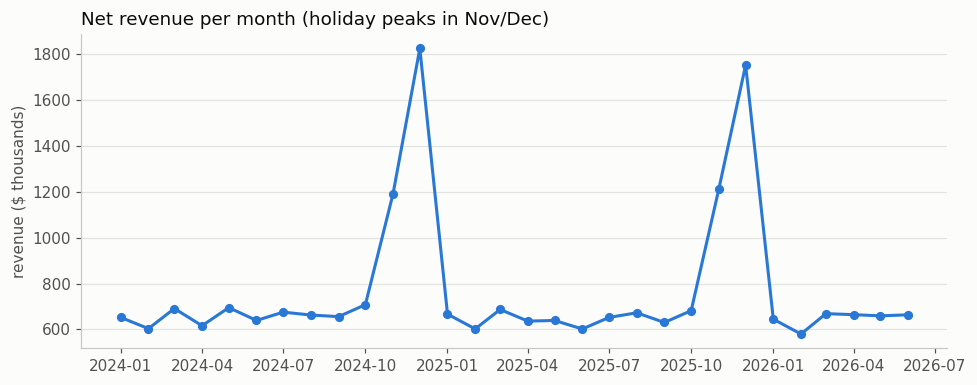

In [13]:
monthly = pd.read_parquet(f"{ANALYTICS}/sales_monthly").sort_values("month")
monthly["revenue"] = monthly["revenue"].astype(float)
fig, ax = plt.subplots(figsize=(9, 3.6), dpi=110)
ax.plot(pd.to_datetime(monthly["month"]), monthly["revenue"] / 1e3, color=BLUE, linewidth=2, marker="o", markersize=5)
style(ax, "Net revenue per month (holiday peaks in Nov/Dec)", ylabel="revenue ($ thousands)")
plt.tight_layout(); plt.show()

In [14]:
by_type = pd.read_parquet(f"{ANALYTICS}/revenue_by_customer_type")
dist = pd.read_parquet(f"{ANALYTICS}/customer_type_distribution")
by_type.merge(dist, on="customer_type")[["customer_type", "pct_of_customers", "pct_of_revenue", "avg_order_value", "order_count"]]

,customer_type,pct_of_customers,pct_of_revenue,avg_order_value,order_count
0,Regular,70.39,52.13,234.20,51030
1,Premium,21.79,27.03,234.45,26434
2,VIP,7.83,20.83,282.76,16892


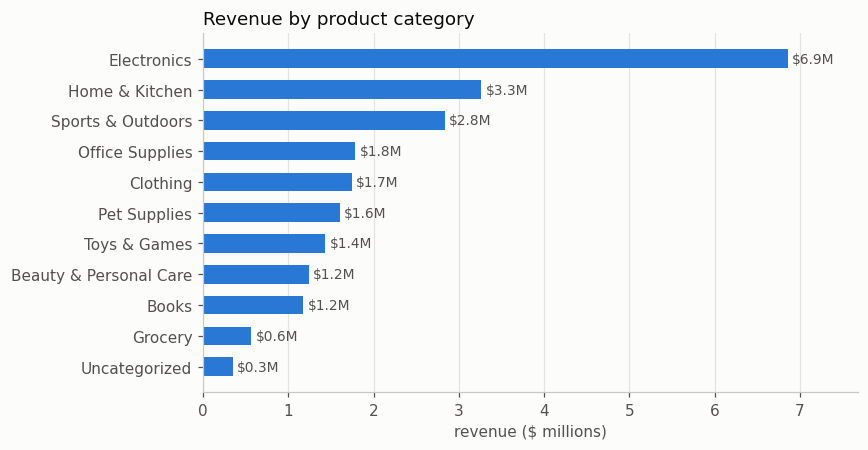

In [15]:
cat = pd.read_parquet(f"{ANALYTICS}/category_performance").sort_values("revenue")
cat["revenue"] = cat["revenue"].astype(float)
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=110)
ax.barh(cat["category"], cat["revenue"] / 1e6, color=BLUE, height=0.6)
for i, v in enumerate(cat["revenue"] / 1e6):
    ax.text(v + 0.05, i, f"${v:.1f}M", va="center", color=MUTED, fontsize=9)
style(ax, "Revenue by product category", xlabel="revenue ($ millions)")
ax.grid(True, axis="x", color=GRID); ax.grid(False, axis="y"); ax.margins(x=0.12)
plt.tight_layout(); plt.show()

In [16]:
pd.read_parquet(f"{ANALYTICS}/top_customers")

,revenue_rank,customer_id,first_name,last_name,customer_type,city,order_count,lifetime_value,avg_order_value
0,1,72633,Dean,Bush,VIP,San Antonio,44,13114.99,298.07
1,2,91177,Jenna,Marsh,VIP,Las Vegas,19,12245.37,644.49
2,3,47766,Bryan,Flores,VIP,Philadelphia,15,11151.98,743.47
3,4,85864,Dorothy,Green,VIP,Philadelphia,28,9923.56,354.41
4,5,90630,Wendy,Cooper,VIP,Phoenix,35,9280.00,265.14
5,6,43252,Holly,Kent,VIP,Omaha,22,9197.03,418.05
6,7,7954,Anita,Webster,VIP,San Diego,31,9114.63,294.02
7,8,61150,Eric,Bolton,VIP,Chicago,17,8977.01,528.06
8,9,94139,Denise,Roth,Premium,Los Angeles,20,8748.56,437.43
9,10,25954,Matthew,Ellis,VIP,Houston,26,8261.16,317.74


In [17]:
pd.read_parquet(f"{ANALYTICS}/top_categories_by_customer_type")

,customer_type,category_rank,category,order_lines,units_sold,revenue
0,Premium,1,Office Supplies,5953,9446,488648.74
1,Premium,2,Beauty & Personal Care,5886,9279,331726.98
2,Premium,3,Sports & Outdoors,5853,9141,772964.02
3,Regular,1,Sports & Outdoors,11496,18149,1485177.86
4,Regular,2,Pet Supplies,11487,18087,834687.92
5,Regular,3,Office Supplies,11454,18091,920332.69
6,VIP,1,Books,4629,7263,254816.29
7,VIP,2,Grocery,4595,7315,115342.72
8,VIP,3,Office Supplies,4538,7201,378261.18


## 6. The same data in PostgreSQL

In [18]:
import psycopg2
conn = psycopg2.connect(host=os.getenv("WAREHOUSE_HOST", "localhost"), port=os.getenv("WAREHOUSE_PORT", "5432"),
                        dbname=os.getenv("WAREHOUSE_DB", "retail_dw"), user=os.getenv("POSTGRES_USER"),
                        password=os.getenv("POSTGRES_PASSWORD"))
pd.read_sql("SELECT * FROM analytics.v_recent_pipeline_runs", conn)

/tmp/ipykernel_75/2149566863.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql("SELECT * FROM analytics.v_recent_pipeline_runs", conn)


,audit_id,run_id,status,start_time,end_time,duration_seconds,records_raw,records_clean,records_rejected,rows_loaded,failed_task
0,3,manual__2026-11-08T20:55:28+00:00,success,2026-11-08 20:55:36.017021+00:00,2026-11-08 20:57:50.608743+00:00,134.6,558746,512156,46590,712885,None
1,2,manual__2026-11-08T19:49:20+00:00,success,2026-11-08 19:51:22.026246+00:00,2026-11-08 19:53:33.628444+00:00,131.6,558746,512156,46590,712885,None
2,1,scheduled__2026-11-07T11:00:00+00:00,success,2026-11-08 19:49:04.449779+00:00,2026-11-08 19:51:20.531499+00:00,136.1,558746,512156,46590,712885,None


In [19]:
pd.read_sql('''
    SELECT c.city, COUNT(*) AS orders, SUM(o.net_amount) AS revenue
    FROM orders o JOIN customers c USING (customer_id)
    GROUP BY c.city ORDER BY revenue DESC LIMIT 5''', conn)

/tmp/ipykernel_75/1296094561.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql('''


,city,orders,revenue
0,Tampa,2124,551640.95
1,Fort Worth,2213,545745.44
2,Pittsburgh,2149,539841.53
3,Albuquerque,2191,529586.64
4,Milwaukee,2189,527317.44


## 7. (Optional) Spark SQL on the cleaned Parquet

In [20]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.master("local[2]").appName("notebook").getOrCreate()
spark.read.parquet(f"{CLEAN}/orders").createOrReplaceTempView("orders")
spark.sql('''
    SELECT payment_method, COUNT(*) AS orders, ROUND(AVG(net_amount), 2) AS avg_order
    FROM orders GROUP BY payment_method ORDER BY orders DESC''').toPandas()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/08 21:00:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                                                

,payment_method,orders,avg_order
0,Credit Card,35086,241.76
1,Debit Card,20038,241.29
2,PayPal,16467,249.64
3,Apple Pay,11163,241.77
4,Gift Card,4618,242.05
5,Bank Transfer,4610,240.47
6,Unknown,2374,240.87


In [21]:
spark.stop(); conn.close()